# AXIOM
## Adversarial Evidence Reconstruction Engine

**Central question:** does the most frequently observed claim actually represent the most probable explanation?

This notebook implements a compact experimental system that combines semantic similarity, evidence dependency, reliability, contradiction, temporal coherence, and counterfactual scoring.

> **Frequency ≠ independent evidence ≠ truth**

The experiment is deliberately synthetic and reproducible. The goal is not to manufacture an oracle, but to make the failure mode of naïve majority reasoning measurable.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

from dataclasses import dataclass
from collections import defaultdict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import AgglomerativeClustering

np.random.seed(42)
pd.set_option("display.max_colwidth", 90)

print("Axiom initialized.")

Axiom initialized.


## 1. Synthetic world

We create three competing hypotheses:

- **H1:** overheating caused the failure
- **H2:** coolant-system failure caused the failure
- **H3:** electrical failure caused the failure

The ground truth is H2.

The important adversarial structure is that several apparent sources repeat the same false H1 narrative. Their volume is high, but their information is not independent.

In [2]:
hypotheses = {
    "H1": "overheating caused the reactor failure",
    "H2": "coolant system failure caused the reactor failure",
    "H3": "electrical failure caused the reactor failure",
}

claims = [
    ("S01", "primary_lab",  "coolant pressure dropped before the reactor failed", 2, 0.95, "H2", +1),
    ("S02", "primary_lab",  "reactor temperature remained normal before failure", 3, 0.92, "H1", -1),
    ("S03", "primary_lab",  "coolant pump showed abnormal behavior", 4, 0.94, "H2", +1),
    ("S04", "maintenance",  "coolant pressure was falling rapidly", 5, 0.88, "H2", +1),
    ("S05", "maintenance",  "no thermal alarm was triggered", 6, 0.86, "H1", -1),
    ("S06", "maintenance",  "electrical readings were within normal limits", 7, 0.83, "H3", -1),
    ("S07", "press_release", "reactor failure was caused by overheating", 8, 0.65, "H1", +1),
    ("S08", "news_01",     "the reactor failed because of overheating", 9, 0.58, "H1", +1),
    ("S09", "news_02",     "reports say overheating caused the failure", 10, 0.54, "H1", +1),
    ("S10", "blog_01",     "overheating was responsible for the reactor failure", 11, 0.42, "H1", +1),
    ("S11", "forum_01",    "people are reporting an overheating failure", 12, 0.30, "H1", +1),
    ("S12", "sensor_log",  "temperature stayed near baseline", 13, 0.97, "H1", -1),
    ("S13", "sensor_log",  "coolant pressure dropped sharply", 14, 0.98, "H2", +1),
    ("S14", "operator",    "the coolant system stopped circulating properly", 15, 0.91, "H2", +1),
    ("S15", "operator",    "electrical supply remained stable", 16, 0.89, "H3", -1),
]

df = pd.DataFrame(claims, columns=[
    "source", "origin", "text", "time", "reliability", "target", "polarity"
])

df

,source,origin,text,time,reliability,target,polarity
0,S01,primary_lab,coolant pressure dropped before the reactor failed,2,0.95,H2,1
1,S02,primary_lab,reactor temperature remained normal before failure,3,0.92,H1,-1
2,S03,primary_lab,coolant pump showed abnormal behavior,4,0.94,H2,1
3,S04,maintenance,coolant pressure was falling rapidly,5,0.88,H2,1
4,S05,maintenance,no thermal alarm was triggered,6,0.86,H1,-1
5,S06,maintenance,electrical readings were within normal limits,7,0.83,H3,-1
6,S07,press_release,reactor failure was caused by overheating,8,0.65,H1,1
7,S08,news_01,the reactor failed because of overheating,9,0.58,H1,1
8,S09,news_02,reports say overheating caused the failure,10,0.54,H1,1
9,S10,blog_01,overheating was responsible for the reactor failure,11,0.42,H1,1


## 2. Pictographical view: the evidence timeline

Each character represents one observation. The arrows show the sequence in which evidence arrives.

The deliberate design makes the false overheating narrative arrive repeatedly after the event, while direct operational evidence appears earlier and is more independent.

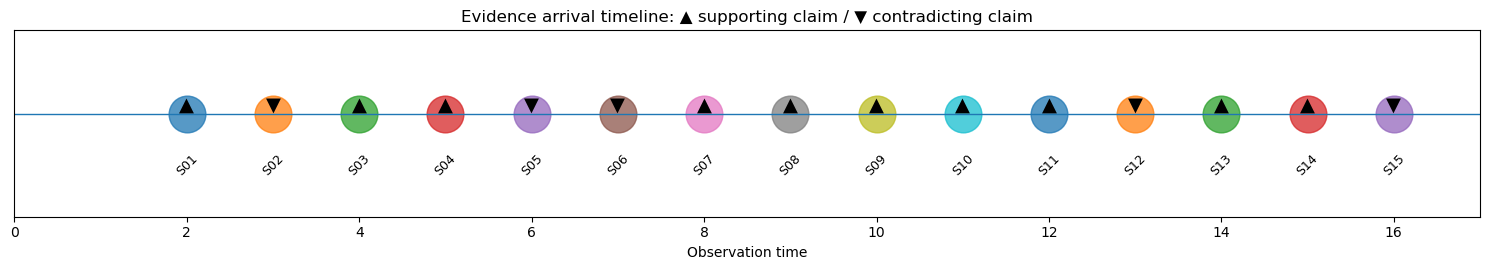

In [3]:
fig, ax = plt.subplots(figsize=(15, 2.8))
for _, r in df.iterrows():
    marker = "▲" if r["polarity"] == 1 else "▼"
    ax.scatter(r["time"], 0, s=700, alpha=0.75)
    ax.text(r["time"], 0.02, marker, ha="center", va="center", fontsize=14)
    ax.text(r["time"], -0.08, r["source"], ha="center", va="top", fontsize=9, rotation=45)

ax.axhline(0, linewidth=1)
ax.set_xlim(0, 17)
ax.set_ylim(-0.22, 0.18)
ax.set_yticks([])
ax.set_xlabel("Observation time")
ax.set_title("Evidence arrival timeline: ▲ supporting claim / ▼ contradicting claim")
plt.tight_layout()
plt.show()

## 3. Semantic representation and claim clustering

Axiom first groups observations that express similar propositions.

For a lightweight baseline we use TF-IDF. This is intentionally boring and interpretable. A production version could replace it with a sentence-transformer embedding model without changing the downstream reasoning interface.

In [4]:
vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
X = vectorizer.fit_transform(df["text"])

sim = cosine_similarity(X)

# Small threshold chosen for the synthetic corpus.
distance = 1 - sim
clusterer = AgglomerativeClustering(
    n_clusters=None,
    metric="precomputed",
    linkage="average",
    distance_threshold=0.58
)
labels = clusterer.fit_predict(distance)
df["claim_cluster"] = labels

cluster_view = df[["source", "text", "claim_cluster"]].sort_values("claim_cluster")
cluster_view

,source,text,claim_cluster
0,S01,coolant pressure dropped before the reactor failed,0
12,S13,coolant pressure dropped sharply,0
14,S15,electrical supply remained stable,1
13,S14,the coolant system stopped circulating properly,2
5,S06,electrical readings were within normal limits,3
11,S12,temperature stayed near baseline,4
7,S08,the reactor failed because of overheating,5
9,S10,overheating was responsible for the reactor failure,6
1,S02,reactor temperature remained normal before failure,7
4,S05,no thermal alarm was triggered,8


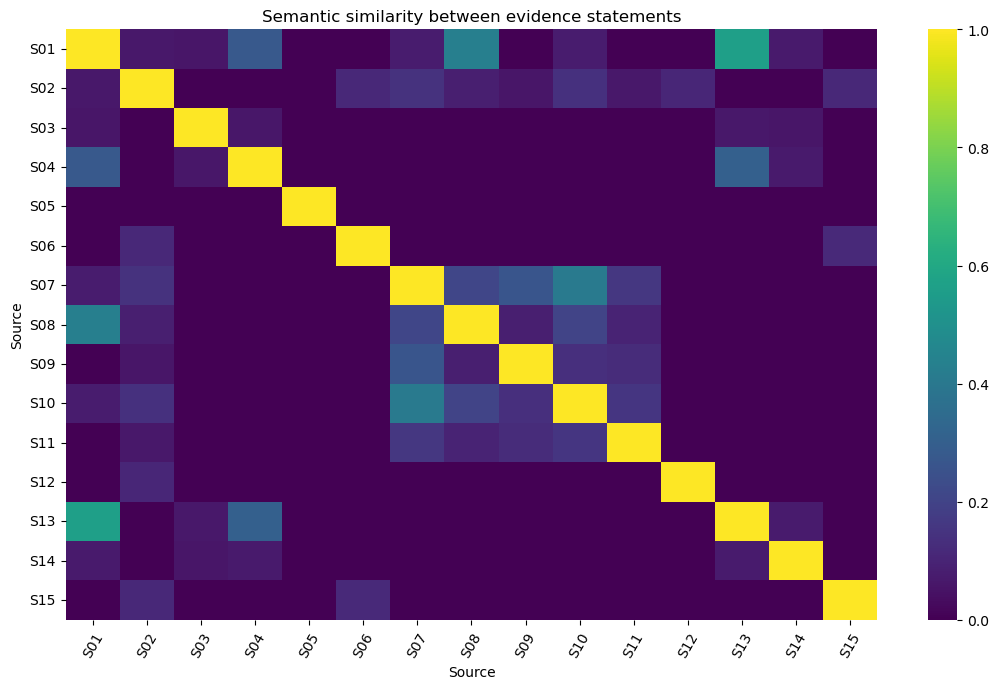

In [5]:
plt.figure(figsize=(11, 7))
sns.heatmap(sim, cmap="viridis", xticklabels=df.source, yticklabels=df.source)
plt.title("Semantic similarity between evidence statements")
plt.xlabel("Source")
plt.ylabel("Source")
plt.xticks(rotation=60)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Evidence dependency

A source can be highly similar to another source because it independently observed the same event, or because it copied the same narrative.

The synthetic provenance graph encodes that distinction.

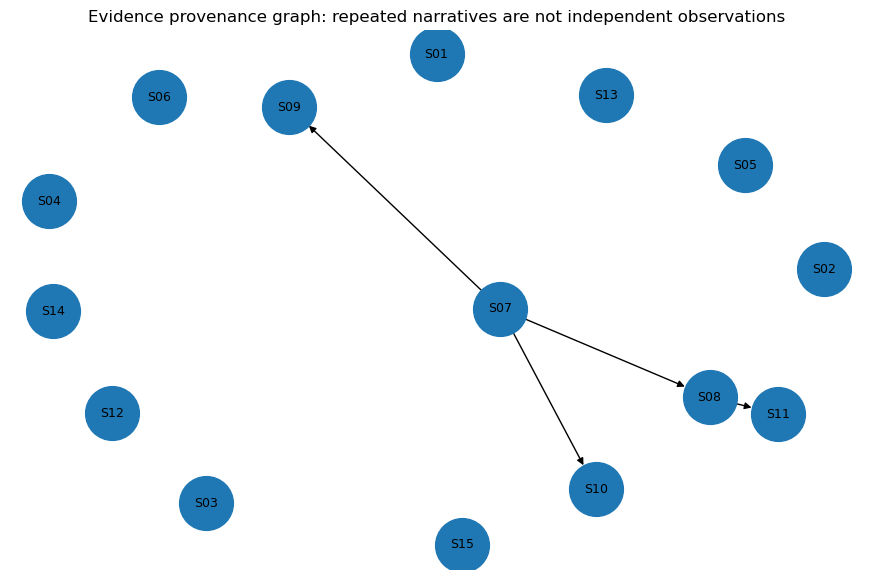

In [6]:
G = nx.DiGraph()

for _, r in df.iterrows():
    G.add_node(r.source, origin=r.origin)

dependencies = [
    ("S07", "S08"), ("S07", "S09"), ("S07", "S10"), ("S08", "S11")
]

for a, b in dependencies:
    G.add_edge(a, b, relation="derived_from")

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(11, 7))
nx.draw_networkx(
    G, pos,
    with_labels=True,
    node_size=1500,
    arrows=True,
    font_size=9
)
plt.title("Evidence provenance graph: repeated narratives are not independent observations")
plt.axis("off")
plt.show()

## 5. Independence correction

Axiom discounts evidence when it appears downstream of another observation.

For this experiment:

\[
d_i = \frac{1}{1+\alpha D_i}
\]

where \(D_i\) is the number of upstream dependencies.

This is intentionally a transparent heuristic rather than a claim that one equation solves source provenance.

In [7]:
alpha = 1.25

upstream_count = {}
for node in G.nodes:
    upstream_count[node] = len(nx.ancestors(G, node))

df["dependency_count"] = df["source"].map(upstream_count).fillna(0)
df["independence"] = 1 / (1 + alpha * df["dependency_count"])

df[["source", "origin", "reliability", "dependency_count", "independence"]]

,source,origin,reliability,dependency_count,independence
0,S01,primary_lab,0.95,0,1.000000
1,S02,primary_lab,0.92,0,1.000000
2,S03,primary_lab,0.94,0,1.000000
3,S04,maintenance,0.88,0,1.000000
4,S05,maintenance,0.86,0,1.000000
5,S06,maintenance,0.83,0,1.000000
6,S07,press_release,0.65,0,1.000000
7,S08,news_01,0.58,1,0.444444
8,S09,news_02,0.54,1,0.444444
9,S10,blog_01,0.42,1,0.444444


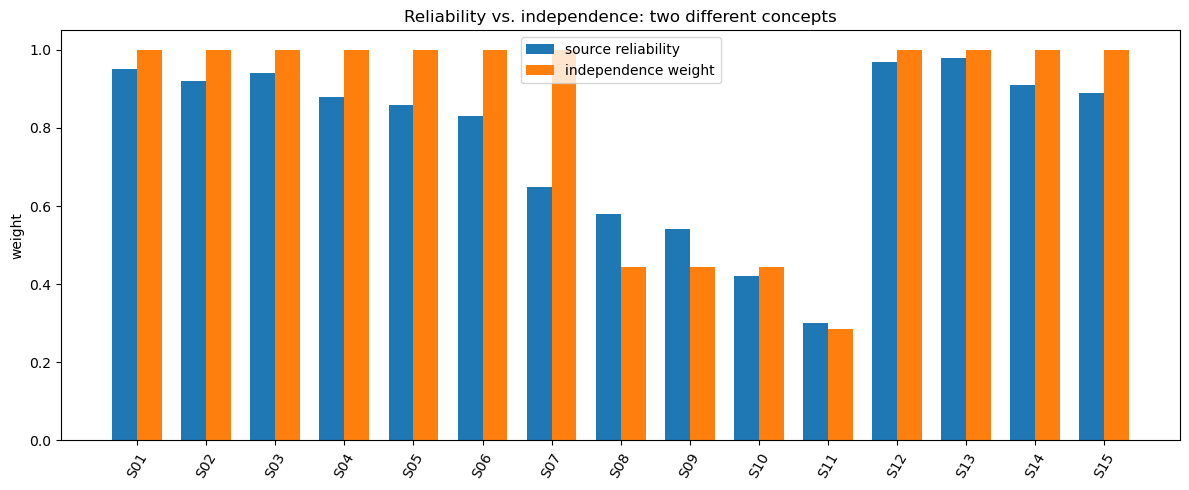

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(df))
ax.bar(x - 0.18, df["reliability"], width=0.36, label="source reliability")
ax.bar(x + 0.18, df["independence"], width=0.36, label="independence weight")
ax.set_xticks(x)
ax.set_xticklabels(df["source"], rotation=60)
ax.set_ylim(0, 1.05)
ax.set_ylabel("weight")
ax.set_title("Reliability vs. independence: two different concepts")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Hypothesis scoring

For each hypothesis, evidence contributes positively or negatively.

The contribution is:

\[
w_i \cdot r_i \cdot d_i \cdot polarity_i
\]

where the polarity is +1 when an observation supports a hypothesis and -1 when it contradicts it.

A simple prior and normalization turn the scores into confidence-like values.

In [9]:
# Evidence compatibility matrix:
# Each row is an observation; each column is a hypothesis.
compat = pd.DataFrame(0.0, index=df.source, columns=hypotheses.keys())

for idx, r in df.iterrows():
    # Primary target gets signed evidence; other hypotheses receive a smaller
    # competing penalty to keep the experiment interpretable.
    for h in hypotheses:
        if h == r.target:
            compat.loc[r.source, h] = r.polarity
        else:
            compat.loc[r.source, h] = -0.25 * r.polarity

weights = df.set_index("source")["reliability"] * df.set_index("source")["independence"]
raw_scores = (compat.mul(weights, axis=0)).sum()

confidence = np.exp(raw_scores - raw_scores.max())
confidence = confidence / confidence.sum()

result = pd.DataFrame({
    "hypothesis": list(hypotheses.values()),
    "raw_score": raw_scores.values,
    "confidence": confidence.values
}, index=raw_scores.index).sort_values("confidence", ascending=False)

result

,hypothesis,raw_score,confidence
H2,coolant system failure caused the reactor failure,5.422460,0.999097
H1,overheating caused the reactor failure,-2.064841,0.000560
H3,electrical failure caused the reactor failure,-2.552540,0.000344


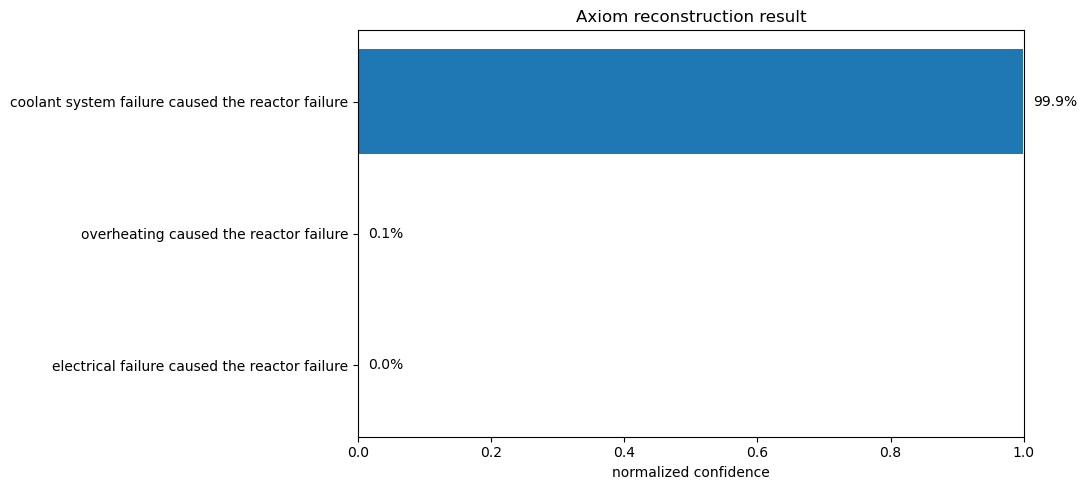

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(result["hypothesis"], result["confidence"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("normalized confidence")
ax.set_title("Axiom reconstruction result")
for bar, value in zip(bars, result["confidence"]):
    ax.text(value + 0.015, bar.get_y() + bar.get_height()/2, f"{value:.1%}", va="center")
plt.tight_layout()
plt.show()

## 7. Majority vote vs. independence-aware reasoning

Now we deliberately construct an adversarial scenario.

The false H1 narrative is repeated many times, while H2 receives fewer but independent observations.

This is the core stress test:

> **Can repetition overwhelm independent evidence?**

In [11]:
def simulate_adversarial(n_false, n_true=10, seed=42):
    rng = np.random.default_rng(seed)

    # False narrative sources are descendants of one origin.
    false = []
    for i in range(n_false):
        false.append({
            "id": f"F{i}",
            "claim": "H1",
            "reliability": rng.uniform(0.35, 0.65),
            "independence": 1 / (1 + 1.8 * (i > 0)),
        })

    # True observations are independent.
    true = []
    for i in range(n_true):
        true.append({
            "id": f"T{i}",
            "claim": "H2",
            "reliability": rng.uniform(0.75, 0.98),
            "independence": 1.0,
        })

    all_obs = false + true
    majority = "H1" if n_false > n_true else "H2"

    scores = defaultdict(float)
    for o in all_obs:
        scores[o["claim"]] += o["reliability"] * o["independence"]

    axiom_choice = max(scores, key=scores.get)
    return majority, axiom_choice, scores

rows = []
for n in range(1, 101, 2):
    majority, axiom_choice, scores = simulate_adversarial(n)
    rows.append({
        "false_sources": n,
        "majority_correct": int(majority == "H2"),
        "axiom_correct": int(axiom_choice == "H2"),
    })

adv = pd.DataFrame(rows)
adv.head()

,false_sources,majority_correct,axiom_correct
0,1,1,1
1,3,1,1
2,5,1,1
3,7,1,1
4,9,1,1


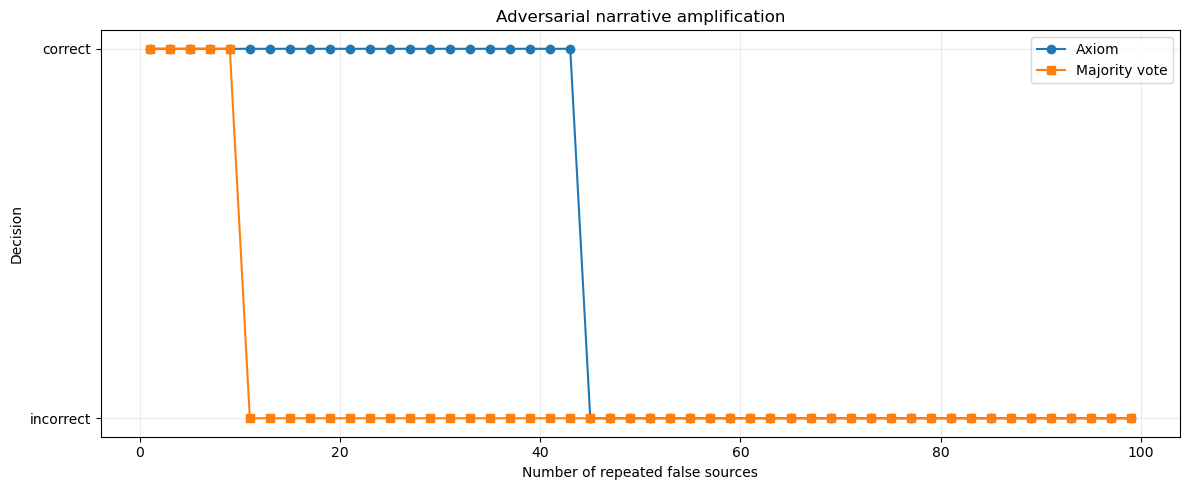

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(adv["false_sources"], adv["axiom_correct"], marker="o", label="Axiom")
ax.plot(adv["false_sources"], adv["majority_correct"], marker="s", label="Majority vote")
ax.set_yticks([0, 1])
ax.set_yticklabels(["incorrect", "correct"])
ax.set_xlabel("Number of repeated false sources")
ax.set_ylabel("Decision")
ax.set_title("Adversarial narrative amplification")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Counterfactual reasoning

Axiom should not only ask whether evidence supports a hypothesis. It should ask whether the hypothesis predicts the evidence we actually observe.

For the synthetic world:

| Hypothesis | Expected observation |
|---|---|
| H1 overheating | elevated temperature / thermal alarms |
| H2 coolant failure | pressure loss / circulation failure |
| H3 electrical failure | abnormal electrical readings |

The observed data contains pressure loss and normal temperature. That creates a strong likelihood asymmetry.

In [13]:
counterfactuals = pd.DataFrame({
    "observation": [
        "coolant pressure dropped",
        "temperature remained normal",
        "coolant circulation degraded",
        "electrical readings remained normal"
    ],
    "H1_overheating": [0.20, 0.10, 0.35, 0.70],
    "H2_coolant_failure": [0.95, 0.80, 0.95, 0.80],
    "H3_electrical_failure": [0.25, 0.75, 0.20, 0.15],
})

counterfactuals

,observation,H1_overheating,H2_coolant_failure,H3_electrical_failure
0,coolant pressure dropped,0.20,0.95,0.25
1,temperature remained normal,0.10,0.80,0.75
2,coolant circulation degraded,0.35,0.95,0.20
3,electrical readings remained normal,0.70,0.80,0.15


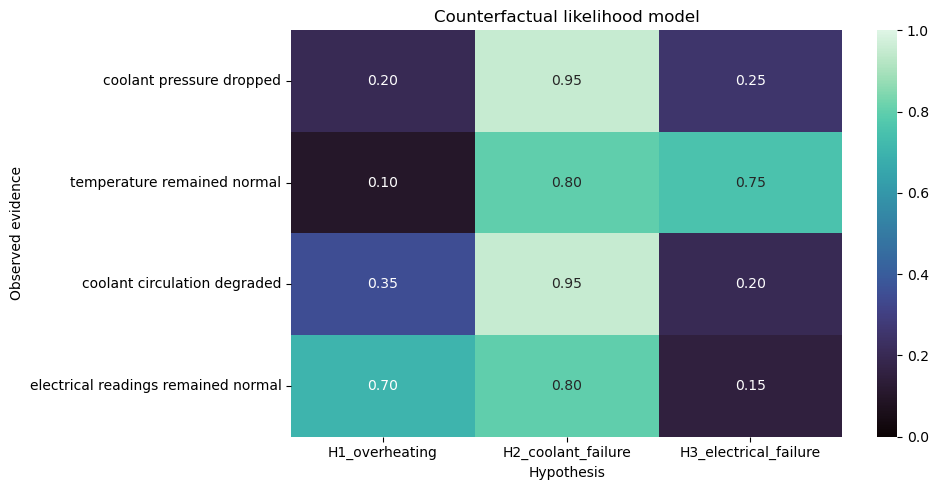

In [14]:
likelihoods = counterfactuals.set_index("observation")
plt.figure(figsize=(10, 5))
sns.heatmap(likelihoods, annot=True, fmt=".2f", cmap="mako", vmin=0, vmax=1)
plt.title("Counterfactual likelihood model")
plt.xlabel("Hypothesis")
plt.ylabel("Observed evidence")
plt.tight_layout()
plt.show()

## 9. Evidence influence matrix

A useful diagnostic is to visualize which observations are actually driving each hypothesis.

This makes the model inspectable rather than producing a mysterious final number.

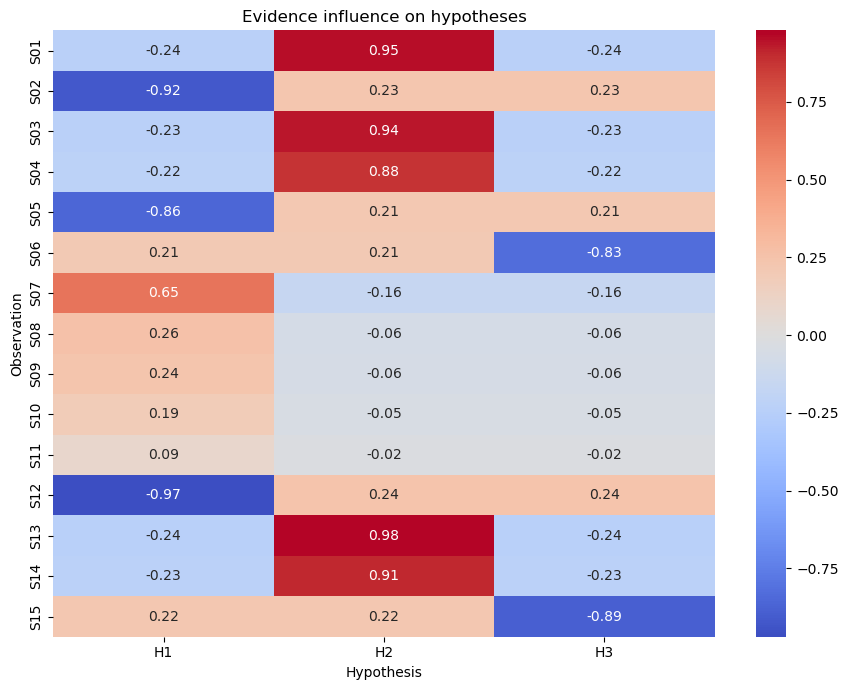

In [15]:
influence = compat.mul(weights, axis=0)

plt.figure(figsize=(9, 7))
sns.heatmap(
    influence,
    center=0,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)
plt.title("Evidence influence on hypotheses")
plt.xlabel("Hypothesis")
plt.ylabel("Observation")
plt.tight_layout()
plt.show()

## 10. Sensitivity analysis

Axiom contains assumptions. The most important one here is the strength of the independence penalty.

If the penalty is too weak, repeated misinformation dominates.

If it is too strong, genuinely independent corroboration can be undercounted.

That tradeoff is itself a research result.

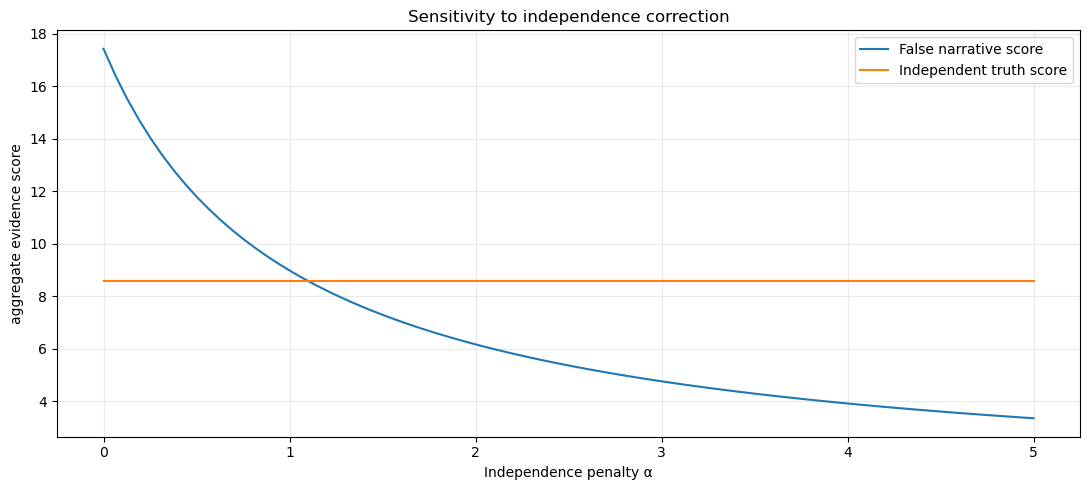

In [16]:
def score_with_alpha(alpha_value, n_false=35, n_true=10, seed=7):
    rng = np.random.default_rng(seed)
    h1 = 0.0
    h2 = 0.0

    for i in range(n_false):
        rel = rng.uniform(0.35, 0.65)
        indep = 1 / (1 + alpha_value * (i > 0))
        h1 += rel * indep

    for _ in range(n_true):
        rel = rng.uniform(0.75, 0.98)
        h2 += rel

    return h1, h2

alphas = np.linspace(0, 5, 80)
sens = []
for a in alphas:
    h1, h2 = score_with_alpha(a)
    sens.append((a, h1, h2))

sens = pd.DataFrame(sens, columns=["alpha", "H1_false", "H2_true"])

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sens["alpha"], sens["H1_false"], label="False narrative score")
ax.plot(sens["alpha"], sens["H2_true"], label="Independent truth score")
ax.set_xlabel("Independence penalty α")
ax.set_ylabel("aggregate evidence score")
ax.set_title("Sensitivity to independence correction")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 11. Final reconstruction

The synthetic ground truth is:

```text
H2 — coolant-system failure
```

The interesting output is not merely whether Axiom gets H2 correct.

The interesting output is **why**:

1. Direct operational evidence supports H2.
2. Multiple observations independently support the same mechanism.
3. The overheating narrative has substantial repetition.
4. Much of that repetition is provenance-dependent.
5. Normal temperature observations contradict overheating.
6. The coolant hypothesis predicts the observed pressure and circulation failures.

This is the central design philosophy:

> **Axiom should expose the structure of its confidence, not merely emit a confidence number.**

In [17]:
winner = result.index[0]
print("RECONSTRUCTED HYPOTHESIS")
print("=" * 60)
print(hypotheses[winner])
print(f"\nConfidence: {result.loc[winner, 'confidence']:.2%}")

print("\nTop evidence:")
top = influence[winner].sort_values(ascending=False).head(5)
for source, value in top.items():
    txt = df.loc[df.source == source, "text"].iloc[0]
    print(f"  + {source}: {value:+.3f} | {txt}")

print("\nStrongest contradictory evidence:")
bottom = influence[winner].sort_values().head(3)
for source, value in bottom.items():
    txt = df.loc[df.source == source, "text"].iloc[0]
    print(f"  - {source}: {value:+.3f} | {txt}")

RECONSTRUCTED HYPOTHESIS
coolant system failure caused the reactor failure

Confidence: 99.91%

Top evidence:
  + S13: +0.980 | coolant pressure dropped sharply
  + S01: +0.950 | coolant pressure dropped before the reactor failed
  + S03: +0.940 | coolant pump showed abnormal behavior
  + S14: +0.910 | the coolant system stopped circulating properly
  + S04: +0.880 | coolant pressure was falling rapidly

Strongest contradictory evidence:
  - S07: -0.163 | reactor failure was caused by overheating
  - S08: -0.064 | the reactor failed because of overheating
  - S09: -0.060 | reports say overheating caused the failure


# Research interpretation

This notebook demonstrates a controlled toy system, not a universal truth detector.

Its portfolio value comes from the *question* and the diagnostics:

\[
\boxed{\text{How should an ML system reason when evidence volume and evidence independence disagree?}}
\]

A natural next step is to turn the synthetic benchmark into a formal evaluation suite and compare:

- majority voting
- raw frequency
- reliability-weighted frequency
- independence-aware scoring
- probabilistic graphical models
- graph neural networks
- retrieval-augmented systems

The most valuable failure case is the one where Axiom is wrong for a principled reason.

That is where the research begins.